## **Problem 1**

In [387]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import copy

from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import brier_score_loss, accuracy_score

### **(c) Multi-Layer Perceptron**

In [388]:
torch.manual_seed(42)

df = pd.read_parquet("taxi_trips.parquet")
print(df.shape)
print(df.columns.tolist())

(523554, 8)
['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'trip_duration', 'min_of_day', 'day_of_week', 'day_of_year']


#### Train / Validation / Test Split

In [389]:
X = df.drop(columns=["trip_duration"]).values.astype("float32")
y = df["trip_duration"].values.astype("float32")

# 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

# Convert to PyTorch tensors
X_train = torch.tensor(X_train)
X_val = torch.tensor(X_val)
X_test = torch.tensor(X_test)

y_train = torch.tensor(y_train)
y_val = torch.tensor(y_val)
y_test = torch.tensor(y_test)

#### Baseline Model

In [390]:
baseline_mu = y_train.mean()
baseline_sigma = y_train.std(unbiased=False)

def nll(y, mu, sigma):
  return torch.log(sigma) + (y - mu)**2 / (2 * sigma**2)

baseline_val = nll(y_val, baseline_mu, baseline_sigma).mean()
baseline_test = nll(y_test, baseline_mu, baseline_sigma).mean()

print("Baseline Validation NLL:", baseline_val.item())
print("Baseline Test NLL:", baseline_test.item())

Baseline Validation NLL: 2.547128677368164
Baseline Test NLL: 2.548582077026367


#### MLP

In [391]:
class GaussianMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(7, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        out = self.net(x)

        mu = out[:, 0]
        sigma = torch.exp(out[:, 1].clamp(-10, 10))

        return mu, sigma

#### Train Model

In [392]:
model = GaussianMLP()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=2048,
    shuffle=True
)

best_loss = float("inf")
patience = 10
wait = 0
for epoch in range(50):
    model.train()

    for xb, yb in loader:
        mu, sigma = model(xb)
        loss = nll(yb, mu, sigma).mean()

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()

    model.eval()
    with torch.no_grad():
        mu, sigma = model(X_val)
        val_loss = nll(y_val, mu, sigma).mean().item()

    if val_loss < best_loss:
        best_loss = val_loss
        best_model = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}: Val NLL = {val_loss:.4f}", flush=True)

    if wait >= patience:
        break

model.load_state_dict(best_model)

print("Best Validation NLL:", best_loss)

Epoch 5: Val NLL = 1.9453
Epoch 10: Val NLL = 1.8263
Epoch 15: Val NLL = 1.7936
Epoch 20: Val NLL = 1.7810
Epoch 25: Val NLL = 1.7651
Epoch 30: Val NLL = 1.7547
Epoch 35: Val NLL = 1.7442
Epoch 40: Val NLL = 1.7418
Epoch 45: Val NLL = 1.7407
Epoch 50: Val NLL = 1.7370
Best Validation NLL: 1.7324918508529663


#### Evaluate on Test Set

In [393]:
model.eval()

with torch.no_grad():
    mu_test, sigma_test = model(X_test)
    mlp_test = nll(y_test, mu_test, sigma_test).mean()

print(f"Baseline Test NLL: {baseline_test.item():.4f}")
print(f"MLP Test NLL:      {mlp_test.item():.4f}")

Baseline Test NLL: 2.5486
MLP Test NLL:      1.8545


The dataset was split into training (70%), validation (15%), and test (15%) sets. As a baseline, Gaussian model was used to predict the training-set mean and standard deviation for all observations.

An MLP with two hidden layers of 64 and 32 neurons was implemented using ReLU activations. The model predicts the conditional mean using an identity link and the conditional standard deviation using an exponential link.

The model was trained using Gaussian negative log-likelihood with the Adam optimizer (learning rate = 0.001), a batch size of 2048, and a maximum of 50 epochs. Early stopping was applied based on validation loss with a patience of 10 epochs.

The best validation NLL was 1.7325. The MLP achieved a lower test NLL than the baseline (1.8545 versus 2.5486), indicating that modeling the conditional mean and standard deviation using the input features improves predictive performance.

### **(e) Probability Prediction and Evaluation**

In [394]:
# Predict probabilities
model.eval()

with torch.no_grad():
    mu, sigma = model(X_test)
    prob = torch.distributions.Normal(mu, sigma).cdf(
        torch.full_like(mu, 45.0)
    ).numpy()

# True labels and predicted labels
trip_train_rate = (y_train < 45).float().mean().item()
trip_actual = (y_test.numpy() < 45).astype(int)
predicted = (prob >= 0.5).astype(int)

# Evaluation
print("Brier Score:", brier_score_loss(trip_actual, prob))
print("Accuracy:", accuracy_score(trip_actual, predicted))

Brier Score: 0.003104389750400882
Accuracy: 0.9964983319326661


In [395]:
baseline_prob = np.full(trip_actual.shape, trip_train_rate)
baseline_pred = (baseline_prob >= 0.5).astype(int)

print(f"Test trips under 45 min: {trip_actual.mean():.2%}")
print(f"Test trips at least 45 min: {(trip_actual == 0).sum():,}")
print(f"Baseline Brier: {brier_score_loss(trip_actual, baseline_prob):.8f}")
print(f"Baseline accuracy: {accuracy_score(trip_actual, baseline_pred):.8f}")

Test trips under 45 min: 99.55%
Test trips at least 45 min: 350
Baseline Brier: 0.00443681
Baseline accuracy: 0.99554333


Using the fitted MLP, the probability that each trip in the held-out test set would take less than 45 minutes was estimated.

The predicted probabilities were evaluated using the Brier score, and classification accuracy was computed by thresholding the probabilities at 0.5.

The test results were:

- Brier score: 0.0031
- Classification accuracy: 0.9965 (99.65%)

Since 99.55% of test trips lasted less than 45 minutes, the majority-class baseline achieved an accuracy of 99.55%. The MLP improved accuracy by approximately 0.10 percentage points. Additionally, the Brier score decreased from 0.00444 for the constant-probability baseline to 0.00310 for the MLP, representing a reduction of approximately 30%.

## **Problem 2**

In [396]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error
from category_encoders import TargetEncoder
from sklearn.linear_model import LinearRegression

### **(a) Cardinality and Data Splitting**

In [397]:
df = pd.read_csv("retail.csv")

df["StockCode"] = df["StockCode"].astype("category")
df["CustomerID"] = df["CustomerID"].astype("category")

print("Shape:", df.shape)
print("Unique StockCodes:", df["StockCode"].nunique())
print("Unique CustomerIDs:", df["CustomerID"].nunique())
print(df["Quantity"].describe())

Shape: (397924, 3)
Unique StockCodes: 3665
Unique CustomerIDs: 4339
count    397924.000000
mean         13.021823
std         180.420210
min           1.000000
25%           2.000000
50%           6.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64


StockCode has 3,665 unique categories and CustomerID has 4,339 unique categories. Therefore, both features have high cardinality.
One-hot encoding would produce approximately 8,004 features, which results in a high-dimensional feature space.

In [398]:
X = df[["StockCode", "CustomerID"]]
y = df["Quantity"]

# 70% train, 15% validation, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42
)

print("Train:", X_train.shape)
print("Validation", X_val.shape)
print("Test:", X_test.shape)

Train: (278546, 2)
Validation (59689, 2)
Test: (59689, 2)


The dataset was randomly split into training (70%), validation (15%), and test (15%) sets.

### **(b) Target Encoding and Regression**

In [399]:
# Log-transform the target
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

# Out-of-fold target encoding
kf = KFold(n_splits=5, shuffle=True, random_state=42)

X_train_te = pd.DataFrame(
    index = X_train.index,
    columns = X_train.columns,
    dtype=float
)

for fit_idx, holdout_idx in kf.split(X_train):
    encoder_fold = TargetEncoder(
        cols=["StockCode", "CustomerID"]
    )

    encoder_fold.fit(
        X_train.iloc[fit_idx],
        y_train_log.iloc[fit_idx]
    )

    X_train_te.iloc[holdout_idx] = encoder_fold.transform(
        X_train.iloc[holdout_idx]
    ).to_numpy()

# Fit encoder on full training data
encoder = TargetEncoder(
    cols=["StockCode", "CustomerID"]
)

encoder.fit(X_train, y_train_log)

X_val_te = encoder.transform(X_val)
X_test_te = encoder.transform(X_test)

# Train linear regression
model_te = LinearRegression()
model_te.fit(X_train_te, y_train_log)

# Evaluate
val_pred = model_te.predict(X_val_te)
test_pred = model_te.predict(X_test_te)

val_mse = mean_squared_error(y_val_log, val_pred)
test_mse = mean_squared_error(y_test_log, test_pred)

print(f"Validation Log-MSE: {val_mse:.4f}")

# Baseline
baseline_pred = np.full(
    len(y_test_log),
    y_train_log.mean()
)

baseline_mse = mean_squared_error(
    y_test_log, baseline_pred
)

print(f"Baseline Test Log-MSE: {baseline_mse:.4f}")
print(f"Target Encoding Test Log-MSE: {test_mse:.4f}")

Validation Log-MSE: 0.3673
Baseline Test Log-MSE: 0.9966
Target Encoding Test Log-MSE: 0.3639


A log transformation was applied to `Quantity` to reduce the influence of extreme values. Five-fold out-of-fold target encoding was used to prevent target leakage in the training set. For the validation and test sets, a target encoder fitted on the full training set was used.

A linear regression model was trained using the target-encoded features and evaluated using mean squared error (MSE) on the log-transformed target. The model was also compared against a baseline that always predicts the mean log-transformed `Quantity` from the training set.

The model achieved a validation log-MSE of 0.3673 and a test log-MSE of 0.3639, compared with a baseline test log-MSE of 0.9966.

The model reduced the test log-MSE by approximately 63.5% relative to the baseline. The similar validation and test errors suggest that the model generalizes reasonably well to unseen data.

### **(c) Neural Network with Embeddings**

#### Categorical Features Encoding

In [400]:
torch.manual_seed(42)

cols = ["StockCode", "CustomerID"]

X_train_emb = pd.DataFrame(index=X_train.index)
X_val_emb = pd.DataFrame(index=X_val.index)
X_test_emb = pd.DataFrame(index=X_test.index)

sizes = []

for col in cols:
    categories = X_train[col].cat.remove_unused_categories().cat.categories
    mapping = {v: i + 1 for i, v in enumerate(categories)}

    X_train_emb[col] = X_train[col].astype(object).map(mapping).fillna(0).astype(int)
    X_val_emb[col] = X_val[col].astype(object).map(mapping).fillna(0).astype(int)
    X_test_emb[col] = X_test[col].astype(object).map(mapping).fillna(0).astype(int)

    sizes.append(len(categories) + 1)

#### Embedding Neural Network

In [401]:
class EmbeddingMLP(nn.Module):
    def __init__(self, sizes):
        super().__init__()

        self.emb1 = nn.Embedding(sizes[0], 8, padding_idx=0)
        self.emb2 = nn.Embedding(sizes[1], 8, padding_idx=0)

        self.net = nn.Sequential(
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        a = self.emb1(x[:, 0])
        b = self.emb2(x[:, 1])

        h = torch.cat([a, b], dim=1)
        return self.net(h).squeeze(1)

In [402]:
Xtr = torch.tensor(X_train_emb.to_numpy(), dtype=torch.long)
Xv = torch.tensor(X_val_emb.to_numpy(), dtype=torch.long)
Xt = torch.tensor(X_test_emb.to_numpy(), dtype=torch.long)

ytr = torch.tensor(y_train_log.to_numpy(), dtype=torch.float32)
yv = torch.tensor(y_val_log.to_numpy(), dtype=torch.float32)

In [403]:
torch.manual_seed(42)

loader = DataLoader(
    TensorDataset(Xtr, ytr),
    batch_size=256,
    shuffle=True
)

model_emb = EmbeddingMLP(sizes)
optimizer = torch.optim.Adam(model_emb.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

best_loss = float("inf")
patience = 5
wait = 0

for epoch in range(100):
  model_emb.train()

  for xb, yb in loader:
      pred = model_emb(xb)
      loss = loss_fn(pred, yb)

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

  model_emb.eval()

  with torch.no_grad():
      val_loss = loss_fn(model_emb(Xv), yv).item()

  if val_loss < best_loss:
      best_loss = val_loss
      best_state = copy.deepcopy(model_emb.state_dict())
      patience = 0
  else:
      patience += 1

  if patience >= 5:
      break

model_emb.load_state_dict(best_state)

print(f"Best Validation Log-MSE: {best_loss:.4f}")

Best Validation Log-MSE: 0.2821


In [404]:
model_emb.eval()

with torch.no_grad():
    test_pred_emb = model_emb(Xt).numpy()

test_mse_emb = mean_squared_error(y_test_log, test_pred_emb)

print(f"Embedding Test Log-MSE: {test_mse_emb:.4f}")
print(f"Target Encoding Test Log-MSE: {test_mse:.4f}")

Embedding Test Log-MSE: 0.2847
Target Encoding Test Log-MSE: 0.3639


A neural network was trained with separate 8-dimensional embedding layers for `StockCode` and `CustomerID`. The embeddings were concatenated and passed through a hidden layer with 32 units and ReLU activation.

The log-transformed `Quantity` was used as the target, and the model was trained using MSE loss with the Adam optimizer (learning rate = 0.001). Early stopping was applied based on validation loss.

The embedding model achieved a validation log-MSE of 0.2821 and a test log-MSE of 0.2847, compared with a test log-MSE of 0.3639 for the target encoding model. This represents approximately a 21.8% reduction in test log-MSE, suggesting that learned embeddings may capture useful information beyond category-level target averages.

### **(d) Combining Target Encoding and Embedding**

In [405]:
class CombinedMLP(nn.Module):
    def __init__(self, sizes):
        super().__init__()

        self.emb1 = nn.Embedding(sizes[0], 8, padding_idx=0)
        self.emb2 = nn.Embedding(sizes[1], 8, padding_idx=0)

        self.net = nn.Sequential(
            nn.Linear(18, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x, x_te):
        a = self.emb1(x[:, 0])
        b = self.emb2(x[:, 1])

        h = torch.cat([a, b, x_te], dim=1)
        return self.net(h).squeeze(1)

In [406]:
Ttr = torch.tensor(X_train_te.to_numpy(), dtype=torch.float32)
Tv = torch.tensor(X_val_te.to_numpy(), dtype=torch.float32)
Tt = torch.tensor(X_test_te.to_numpy(), dtype=torch.float32)

In [407]:
torch.manual_seed(42)

loader = DataLoader(
    TensorDataset(Xtr, Ttr, ytr),
    batch_size=256,
    shuffle=True
)

model_comb = CombinedMLP(sizes)
optimizer = torch.optim.Adam(model_comb.parameters(), lr=0.001)
loss_fn = nn.MSELoss()

best_loss = float("inf")
best_comb_state = None
patience = 5
wait = 0

for epoch in range(100):
    model_comb.train()

    for xb, tb, yb in loader:
        pred = model_comb(xb, tb)
        loss = loss_fn(pred, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model_comb.eval()

    with torch.no_grad():
        val_loss = loss_fn(model_comb(Xv, Tv), yv).item()

    if val_loss < best_loss:
        best_loss = val_loss
        best_comb_state = copy.deepcopy(model_comb.state_dict())
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        break

model_comb.load_state_dict(best_comb_state)

print(f"Best Validation Log-MSE: {best_loss:.4f}")

Best Validation Log-MSE: 0.2919


In [408]:
model_comb.eval()

with torch.no_grad():
    test_pred_comb = model_comb(Xt, Tt).numpy()

test_mse_comb = mean_squared_error(y_test_log, test_pred_comb)

print(f"Combined Test Log-MSE: {test_mse_comb:.4f}")
print(f"Embedding Test Log-MSE: {test_mse_emb:.4f}")
print(f"Target Encoding Test Log-MSE: {test_mse:.4f}")

Combined Test Log-MSE: 0.2946
Embedding Test Log-MSE: 0.2847
Target Encoding Test Log-MSE: 0.3639


In [409]:
results = pd.DataFrame({
    "Model": [
        "Target Encoding + Linear Regression",
        "Embedding MLP",
        "Combined MLP"
    ],
    "Test Log-MSE": [
        test_mse,
        test_mse_emb,
        test_mse_comb
    ]
})

display(results)

,Model,Test Log-MSE
0,Target Encoding + Linear Regression,0.363893
1,Embedding MLP,0.284707
2,Combined MLP,0.294578


The combined model used an 18-dimensional input consisting of two 8-dimensional embeddings and two target-encoded features.

The model was trained using MSE loss on the log-transformed target, with the Adam optimizer and early stopping based on validation loss.

The combined model achieved a validation log-MSE of 0.2919 and a test log-MSE of 0.2946. It outperformed the target encoding model (0.3639) but performed slightly worse than the embedding-only model (0.2847).

These results suggest that adding target-encoded features did not provide additional predictive benefits beyond the learned embeddings in this experiment.

## **Problem 3**

In [410]:
from typing import Callable, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import mean_squared_error
from torch.utils.data import DataLoader, TensorDataset

### **(a) Data visualization**

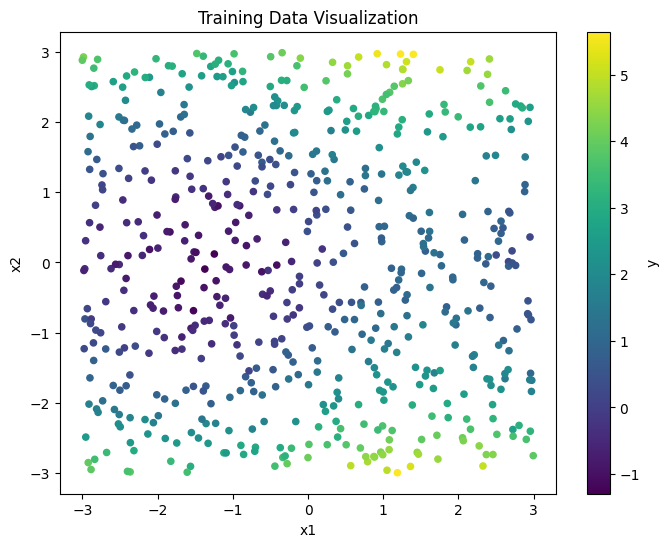

In [411]:
train = pd.read_csv("train.csv")

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    train["x1"],
    train["x2"],
    c=train["y"],
    cmap="viridis",
    s=20
)

plt.colorbar(scatter, label="y")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Training Data Visualization")
plt.show()

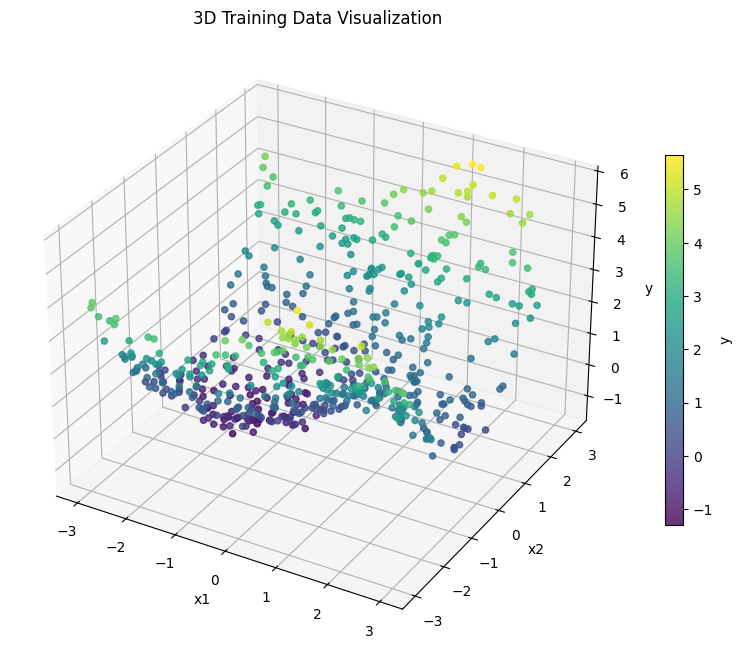

In [412]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    train["x1"],
    train["x2"],
    train["y"],
    c=train["y"],
    cmap="viridis",
    s=20,
    alpha=0.8
)

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("y")
ax.set_title("3D Training Data Visualization")

fig.colorbar(scatter, ax=ax, shrink=0.6, label="y")

plt.show()

The 2D and 3D visualizations suggest a nonlinear relationship between the input features and the target variable.

### **(b) Random Kitchen Sink with Ridge Regression**

In [413]:
val = pd.read_csv("val.csv")

X_train = train[["x1", "x2"]].to_numpy()
y_train = train["y"].to_numpy()

X_val = val[["x1", "x2"]].to_numpy()
y_val = val["y"].to_numpy()

In [414]:
class RandomKitchenSinks:

  def __init__(self, D=1000, sigma=1.0, ridge_lambda=1e-3):

    self.D = D
    self.sigma = sigma
    self.ridge_lambda = ridge_lambda

    h = D // 2

    self.W = np.random.normal(
        loc=0,
        scale=1 / sigma,
        size=(2, h)
    )

    self.b = np.random.uniform(
        low=0,
        high=2 * np.pi,
        size=h
    )

  def _features(self, X: np.ndarray) -> np.ndarray:
    # Convert the input data X into the random kitchen sinks features.
    # The resulting features should be of shape (n, D or D[+1]), where the plus one is for the intercept term

    Z = X @ self.W + self.b

    phi_sin = np.sin(Z)
    phi_cos = np.cos(Z)

    phi = np.column_stack([phi_sin, phi_cos])

    intercept = np.ones((X.shape[0], 1))

    phi = np.column_stack([intercept, phi])

    return phi

  def fit(self, X: np.ndarray, y: np.ndarray):
    # Fit the ridge regression model to the (1) features computed from the input data X and
    # (2) target values y

    phi = self._features(X)

    penalty = self.ridge_lambda * np.eye(phi.shape[1])
    penalty[0, 0] = 0

    self.coef_ = np.linalg.solve(
        phi.T @ phi + penalty,
        phi.T @ y
    )

  def predict(self, X: np.ndarray) -> np.ndarray:
    # Predict the target values from the input data X

    phi = self._features(X)  # shape (n, D or D[+1])

    return phi @ self.coef_ # shape (n,)

In [415]:
def sweep_rks_model(sweep_D: List[int], X_train, y_train, X_val, y_val):
  # sweeps over the number of random features D

  best_model = None
  best_val_mse = float('inf')
  best_D = None

  train_mses = []
  val_mses = []

  for D in sweep_D:
    # fit the model and get the validation MSE

    model = RandomKitchenSinks(
        D=D,
        sigma=1.0,
        ridge_lambda=1e-3
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_mse = mean_squared_error(y_train, train_pred)
    val_mse = mean_squared_error(y_val, val_pred)

    train_mses.append(train_mse)
    val_mses.append(val_mse)

    if val_mse < best_val_mse:
      best_model = model
      best_val_mse = val_mse
      best_D = D

  return best_model, best_val_mse, best_D, train_mses, val_mses

In [416]:
np.random.seed(42)

sweep_D = [10, 20, 50, 100, 200, 500]

best_rks, best_val_mse, best_D, train_mses, val_mses = sweep_rks_model(
    sweep_D,
    X_train,
    y_train,
    X_val,
    y_val
)

print("Best D:", best_D)
print("Best Validation MSE:", best_val_mse)

Best D: 50
Best Validation MSE: 0.03786024303439838


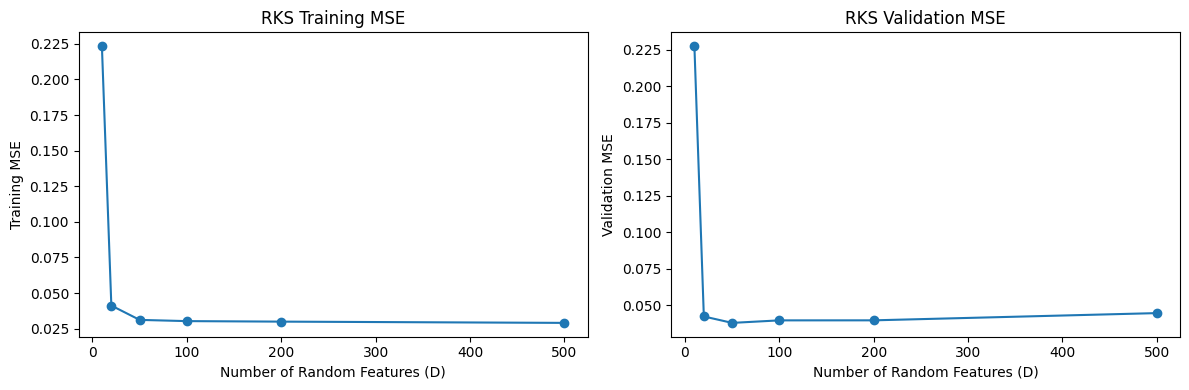

In [417]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(sweep_D, train_mses, marker="o")
axes[0].set_xlabel("Number of Random Features (D)")
axes[0].set_ylabel("Training MSE")
axes[0].set_title("RKS Training MSE")

axes[1].plot(sweep_D, val_mses, marker="o")
axes[1].set_xlabel("Number of Random Features (D)")
axes[1].set_ylabel("Validation MSE")
axes[1].set_title("RKS Validation MSE")

plt.tight_layout()
plt.show()

The number of random features $D$ was tuned over the values $[10, 20, 50, 100, 200, 500]$, while keeping $\sigma=1.0$ and the ridge regularization parameter $\lambda=0.001$ fixed.

The training MSE generally decreased as $D$ increased. However, the validation MSE reached its minimum at $D=50$ and increased slightly for larger values of $D$. This suggests that adding more random features does not necessarily improve generalization performance.

The best model used $D=50$ random features and achieved a validation MSE of 0.03786.

### **(c) 1-Hidden Layer Multi-Layer Perceptron**

In [418]:
class MLP(nn.Module):
  # 1-hidden-layer MLP for regression
  def __init__(self, d_in, d_hidden=128, d_out=1, lr=1e-3, batch_size=128, activation="relu", device="cpu"):
    # d_hidden: hidden dimension
    # activation: activation function
    # lr: learning rate
    # batch_size: batch size

    super().__init__()

    self.device = device
    self.lr = lr
    self.batch_size = batch_size

    self.net = nn.Sequential(
        nn.Linear(d_in, d_hidden),
        nn.ReLU(),
        nn.Linear(d_hidden, d_out)
    ).to(self.device)

  def fit(self, X: np.ndarray, y: np.ndarray):
    # turn the numpy data into torch tensors and move to the device
    X = torch.from_numpy(X).float().to(self.device)
    y = torch.from_numpy(y).float().view(-1, 1).to(self.device)

    dataset = TensorDataset(X, y)
    loader = DataLoader(
        dataset,
        batch_size=self.batch_size,
        shuffle=True
    )

    optimizer = torch.optim.Adam(
        self.net.parameters(),
        lr=self.lr
    )

    loss_fn = nn.MSELoss()
    num_epochs = 1000

    self.net.train()  # make sure to set the model to training mode

    for epoch in range(num_epochs):

      for X_batch, y_batch in loader:

        optimizer.zero_grad()
        predictions = self.forward(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()

    return self

  def forward(self, X: torch.Tensor) -> torch.Tensor:
    return self.net(X)

  def predict(self, X: np.ndarray) -> np.ndarray:
    with torch.no_grad():
      X = torch.from_numpy(X).float().to(self.device)
      return self.forward(X).detach().cpu().numpy()

In [419]:
def mlp_sweep(sweep_values: List[float], X_train, y_train, X_val, y_val):

  best_model = None
  best_val_mse = float('inf')
  best_hidden = None

  train_mses = []
  val_mses = []

  for hidden in sweep_values:

    torch.manual_seed(42)

    model = MLP(
        d_in=2,
        d_hidden=hidden,
        d_out=1,
        lr=1e-3,
        batch_size=128,
        activation="relu",
        device="cpu"
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_mse = mean_squared_error(y_train, train_pred)
    val_mse = mean_squared_error(y_val, val_pred)

    train_mses.append(train_mse)
    val_mses.append(val_mse)

    print(
        f"Hidden={hidden:3d} | "
        f"Train MSE={train_mse:.6f} | "
        f"Val MSE={val_mse:.6f}"
    )

    if val_mse < best_val_mse:
      best_model = model
      best_val_mse = val_mse
      best_hidden = hidden

  return best_model, best_val_mse, best_hidden, train_mses, val_mses

In [420]:
sweep_hidden = [16, 32, 64, 128]

best_mlp, best_mlp_val_mse, best_hidden, mlp_train_mses, mlp_val_mses = mlp_sweep(
    sweep_hidden,
    X_train,
    y_train,
    X_val,
    y_val
)

print("\nBest Hidden Dimension:", best_hidden)
print("Best Validation MSE:", best_mlp_val_mse)

Hidden= 16 | Train MSE=0.043929 | Val MSE=0.048891
Hidden= 32 | Train MSE=0.034417 | Val MSE=0.043502
Hidden= 64 | Train MSE=0.030986 | Val MSE=0.039894
Hidden=128 | Train MSE=0.029742 | Val MSE=0.039233

Best Hidden Dimension: 128
Best Validation MSE: 0.039233469166772214


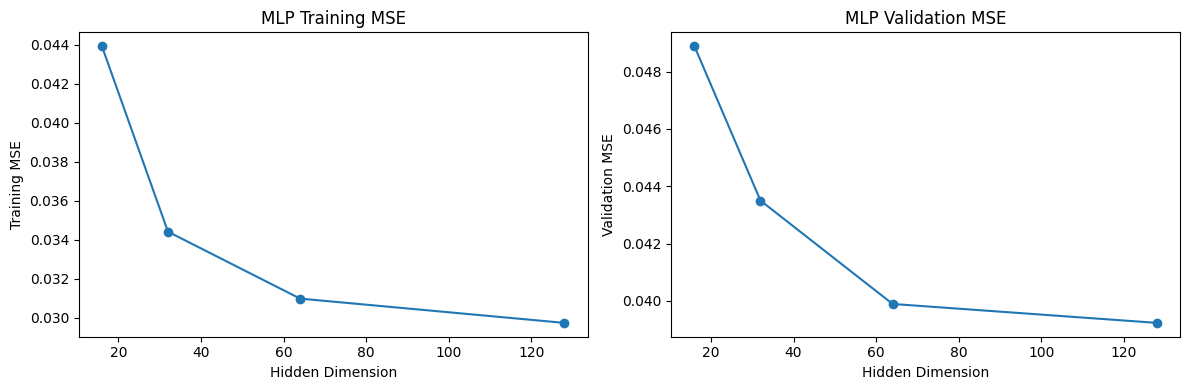

In [421]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(sweep_hidden, mlp_train_mses, marker="o")
axes[0].set_xlabel("Hidden Dimension")
axes[0].set_ylabel("Training MSE")
axes[0].set_title("MLP Training MSE")

axes[1].plot(sweep_hidden, mlp_val_mses, marker="o")
axes[1].set_xlabel("Hidden Dimension")
axes[1].set_ylabel("Validation MSE")
axes[1].set_title("MLP Validation MSE")

plt.tight_layout()
plt.show()

A one-hidden-layer MLP was trained with hidden widths of 16, 32, 64, and 128, while keeping the learning rate, batch size, and the number of epochs fixed.

Both training and validation MSE decreased as the hidden width increased over the tested range. A hidden width of 128 was selected because it achieved the lowest validation MSE among the four candidates.

The selected model achieved a training MSE of 0.02974.

### **(d) Comparison and visualization**

In [422]:
def plot_surface_2d(model_fn: Callable[[np.ndarray], np.ndarray] | nn.Module,
                    xlim: Tuple[float, float], ylim: Tuple[float, float],
                    title: str = "Fitted surface", filename: str = "surface.png", grid: int = 200):
    """
    An example plotting function that handles both callable functions (e.g. model.predict) for a sk-learn-like model and a PyTorch NN.

    Example usage:
    >>> # some model with a `.predict` method
    >>> rks_model = fit_rks_model(X_train, y_train)
    >>> plot_surface_2d(rks_model.predict, (-3, 3), (-3, 3), title="RKS surface")
    >>> # some PyTorch model
    >>> mlp_model = fit_mlp_model(X_train, y_train)
    >>> # direct feed it to the plotting function, no need to call `.predict`
    >>> plot_surface_2d(mlp_model, (-3, 3), (-3, 3), title="MLP surface")
    """
    xs = np.linspace(xlim[0], xlim[1], grid)
    ys = np.linspace(ylim[0], ylim[1], grid)
    X1, X2 = np.meshgrid(xs, ys)
    Xgrid = np.stack([X1.ravel(), X2.ravel()], axis=1)
    if isinstance(model_fn, nn.Module):
        with torch.no_grad():
            X_grid = torch.from_numpy(Xgrid).float().to(next(model_fn.parameters()).device)
            Z = model_fn(X_grid).cpu().numpy().reshape(grid, grid)
    else:
        Z = model_fn(Xgrid).reshape(grid, grid)

    plt.figure()
    plt.contourf(X1, X2, Z, levels=30)  # default colormap
    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.colorbar(label="pred")
    plt.tight_layout()
    # or if you want to directly show it
    # plt.show()
    plt.savefig(filename, dpi=300)

In [423]:
np.random.seed(42)
rks_final = RandomKitchenSinks(
    D=best_D,
    sigma=1.0,
    ridge_lambda=1e-3,
)
rks_final.fit(X_train, y_train)

torch.manual_seed(42)
mlp_final = MLP(
    d_in=X_train.shape[1],
    d_hidden=best_hidden,
    d_out=1,
    lr=1e-3,
    batch_size=128,
    device="cpu",
)
mlp_final.fit(X_train, y_train)
mlp_final.eval()

rks_val_pred = rks_final.predict(X_val).ravel()
mlp_val_pred = mlp_final.predict(X_val).ravel()

In [424]:
comparison = pd.DataFrame({
    "Model": ["RKS", "MLP"],
    "Selected hyperparameter": [f"D = {best_D}", f"hidden = {best_hidden}"],
    "Validation MSE": [
        mean_squared_error(y_val, rks_val_pred),
        mean_squared_error(y_val, mlp_val_pred),
    ],
})
display(comparison.sort_values("Validation MSE", ignore_index=True))

,Model,Selected hyperparameter,Validation MSE
0,RKS,D = 50,0.036788
1,MLP,hidden = 128,0.039233


In [425]:
X_test = pd.read_csv("test.csv")[["x1", "x2"]].to_numpy()

pd.DataFrame({"y": rks_final.predict(X_test).ravel()}).to_csv(
    "rks_test_predictions.csv", index=False, header=False
)
pd.DataFrame({"y": mlp_final.predict(X_test).ravel()}).to_csv(
    "mlp_test_predictions.csv", index=False, header=False
)

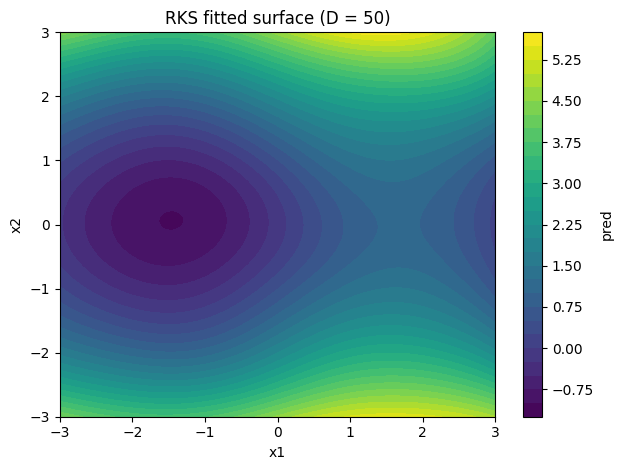

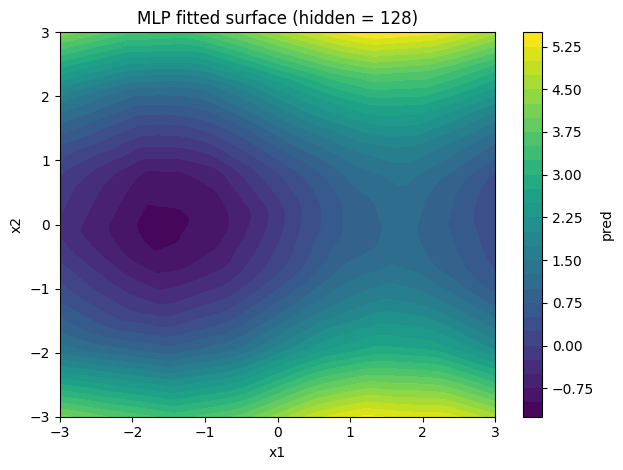

In [426]:
plot_surface_2d(
    rks_final.predict, (-3, 3), (-3, 3),
    title=f"RKS fitted surface (D = {best_D})",
    filename="rks_surface.png"
)
plot_surface_2d(
    mlp_final, (-3, 3), (-3, 3),
    title=f"MLP fitted surface (hidden = {best_hidden})",
    filename="mlp_surface.png"
)
plt.show()

After refitting both models on the training set, RKS achieved a validation MSE of 0.036788, compared with 0.039233 for the MLP. Both models captured the low-response region near $(-1.5, 0)$ and the higher responses near the top and bottom of the training scatterplot. Around the low-response region, the RKS contours were rounded, while the ReLU MLP contours were more angular. The smooth sinusoidal features may have helped RKS capture the gradual changes in the response, contributing to its lower validation error.